# Prediksi Harga jual Mobil Bekas dengan Decision Tree

# **1. Bussines Understanding**


## **1.1 Latar Belakang**

Sebuah perusahaan atau platform jual beli kendaraan ingin membangun sistem
kecerdasan buatan untuk memperkirakan harga jual mobil
bekas secara otomatis berdasarkan karakteristik kendaraan dan kondisi
penggunaannya. Sistem ini bertujuan membantu penjual maupun pembeli dalam
memperoleh estimasi harga kendaraan tanpa harus melakukan penilaian secara
manual.

## **1.2 Tujuan**

Membangun kecedasan buatan untuk memprediksi harga jual mobil bekas berdasarkan karakteristik kendaraan dan kondisi penggunaannya tanpa harus melakukan penilaian atau peninjauan secara manual.

## **1.3 Masalah**

Dalam proses penilaian atau peninjauan mobil bekas, penjual atau pembeli masih memperkirakan harga secara manual sehingga itu memhabiskan waktu yang lama dan tidak efisien.

## **1.4 Solusi**

Membangun kecedasan buatan atau machine learning untuk memprediksi harga jual mobil bekas secara otomatis dengan menggunakan machine learning menggunakan algoritma Decision Tree.

## **1.5 Deskripsi Tabel**

`Fitur Input (8 kolom atribut kendaraan yang digunakan untuk memperkirakan hargajual, ya) meliputi:`
- Car_Name: Nama atau model kendaraan yang dijual.
- Year: Tahun produksi kendaraan.
- Present_Price: Harga kendaraan saat ini berdasarkan data yang tersedia.
- Kms_Driven: Jarak tempuh kendaraan.
- Fuel_Type: Jenis bahan bakar yang digunakan kendaraan (Petrol, Diesel,
CNG).
- Seller_Type: Jenis penjual kendaraan (Dealer atau Individual).
- Transmission: Jenis transmisi kendaraan (Manual atau Automatic).
- Owner: Informasi jumlah atau kategori kepemilikan sebelumnya berdasarkan
nilai yang tercatat dalam dataset.

`Target (Y): `
- Kolom Selling_Price yang berisi nilai harga jual kendaraan dan menjadi
variabel yang akan diprediksi oleh model Machine Learning.`


# **2. Data Preprocessing**

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tkinter as tk
from tkinter import ttk
from tkinter import filedialog
from tkinter import messagebox
from datetime import date


In [38]:
df = pd.read_csv('../dataset/cardekho_data.csv')


In [39]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [40]:
print("Jumlah Baris:", df.shape[0])
print('=======================================')
print("Jumlah Kolom Column:", df.shape[1])
print('=======================================')
print('Frame Data:', df.size)


Jumlah Baris: 301
Jumlah Kolom Column: 9
Frame Data: 2709


In [41]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Seller_Type    301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [42]:
hasil_na = pd.DataFrame({'Mising Value': df.isnull().sum(), 'Persentase Missing Value': df.isnull().sum() / len(df) * 100})
hasil_na.sort_values(by='Persentase Missing Value', ascending=False)

,Mising Value,Persentase Missing Value
Car_Name,0,0.0
Year,0,0.0
Selling_Price,0,0.0
Present_Price,0,0.0
Kms_Driven,0,0.0
Fuel_Type,0,0.0
Seller_Type,0,0.0
Transmission,0,0.0
Owner,0,0.0


In [43]:
df.isnull().sum().sum()

np.int64(0)

In [44]:
print('Jumlah Duplicate :', df.duplicated().sum())

Jumlah Duplicate : 2


# **3. Exploratory Data Analysis**

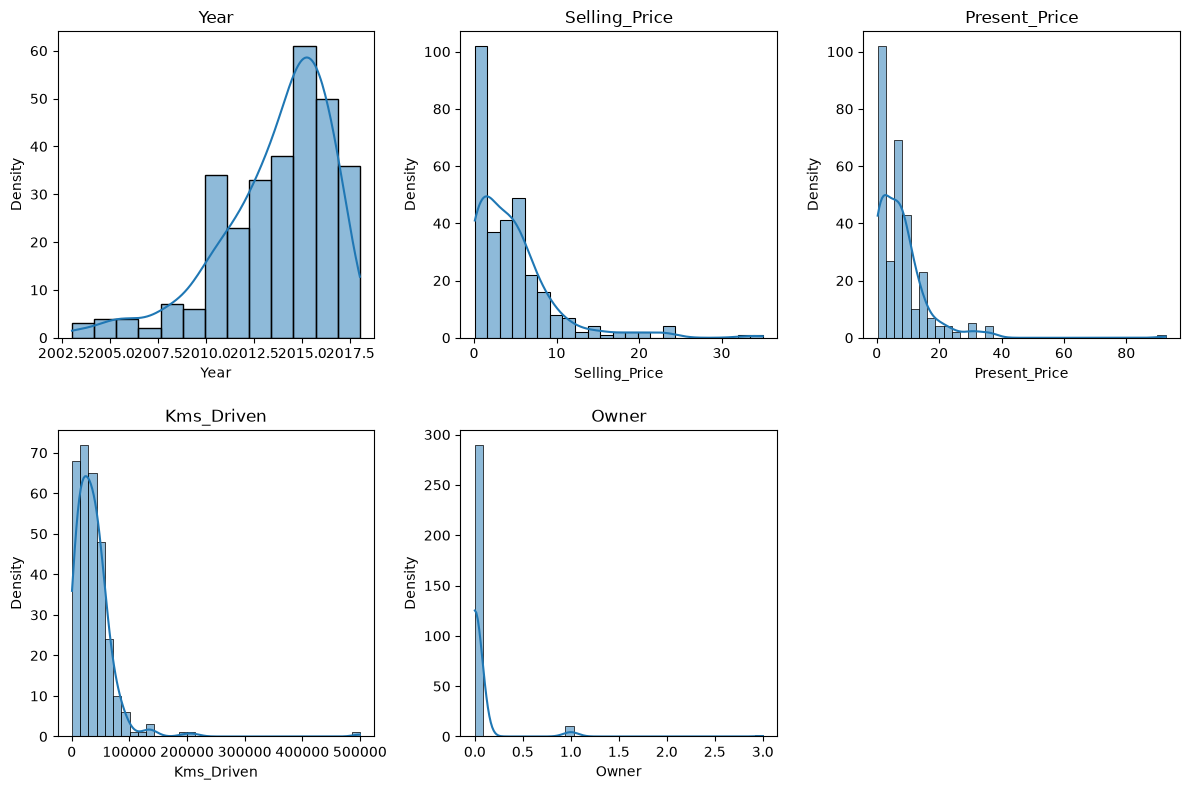

In [45]:
col = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 8))

for i, col in enumerate(col, start=1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel('Density')

plt.tight_layout(h_pad=2)
plt.show()


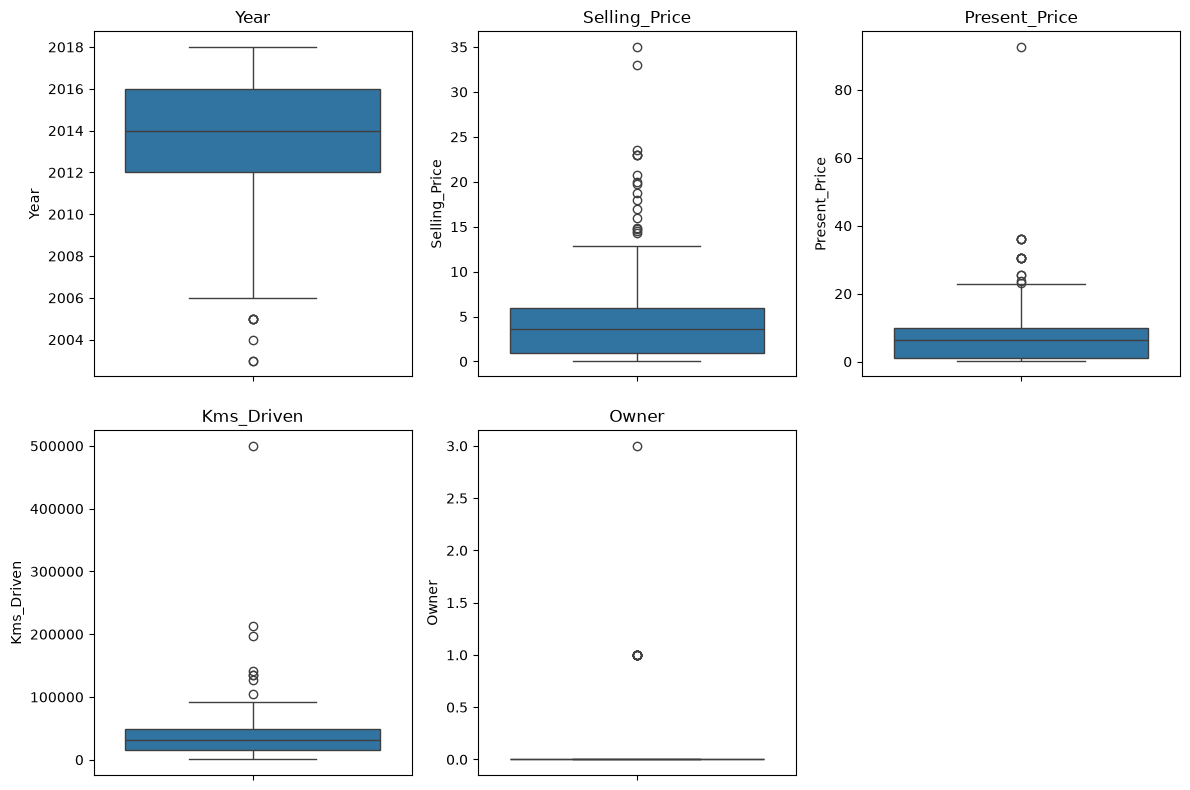

In [46]:
col = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 8))

for i, col in enumerate(col, start=1):
    plt.subplot(2, 3, i)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2)
plt.show()


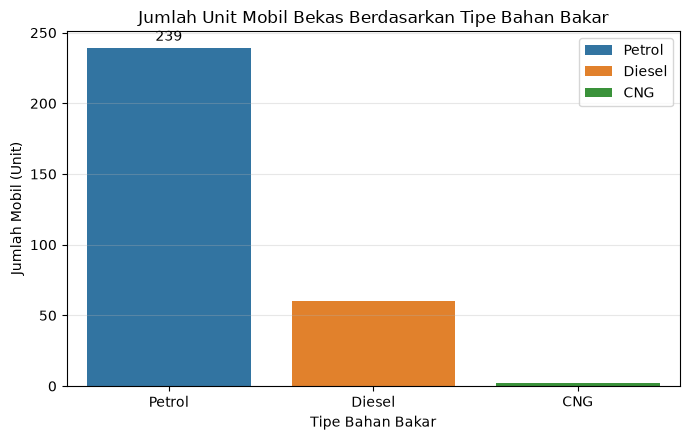

In [47]:
plt.figure(figsize=(7, 4.5))
fuel_order = df['Fuel_Type'].value_counts().index
ax = sns.countplot(x='Fuel_Type', data=df, order=fuel_order, hue='Fuel_Type', legend=False)

plt.title('Jumlah Unit Mobil Bekas Berdasarkan Tipe Bahan Bakar')
plt.xlabel('Tipe Bahan Bakar')
plt.ylabel('Jumlah Mobil (Unit)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(labels=fuel_order)
plt.tight_layout()

ax.bar_label(ax.containers[0], padding=3)
plt.show()


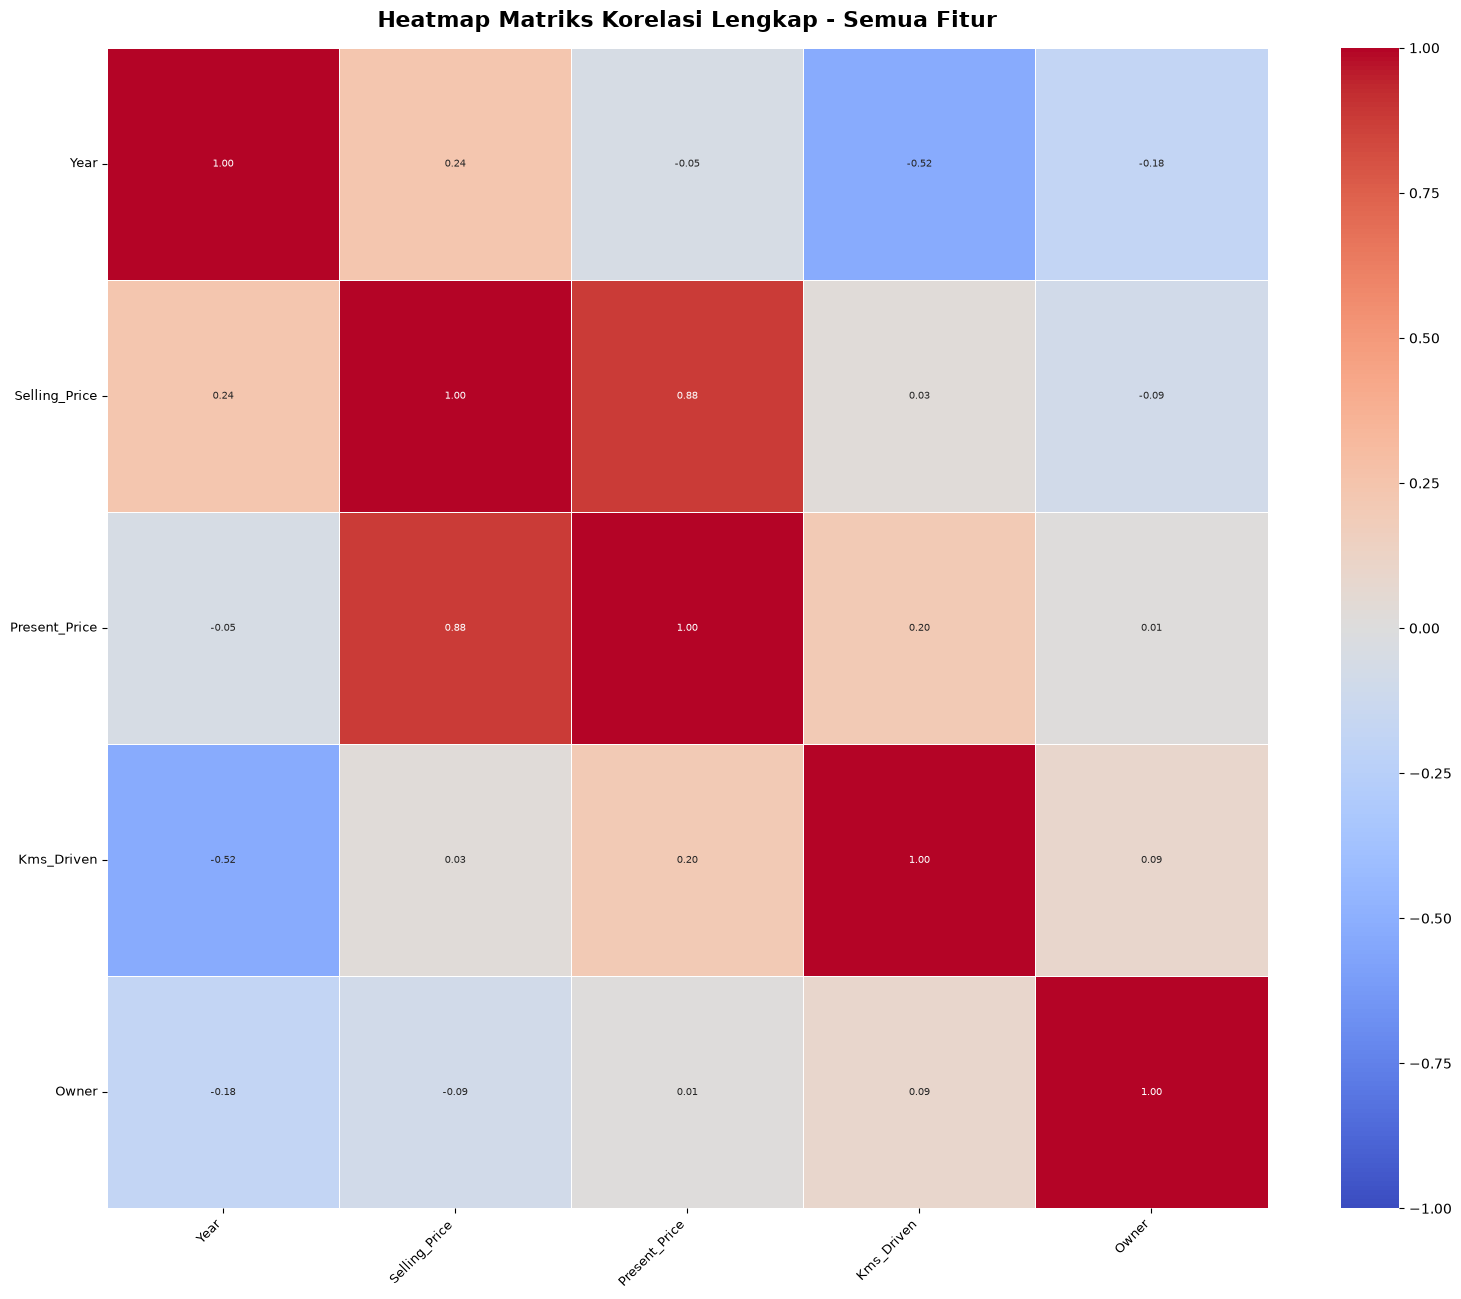

In [48]:
df_corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(16, 13))
sns.heatmap(
    df_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    square=True,
    annot_kws={'size': 7.5}
)
plt.title('Heatmap Matriks Korelasi Lengkap - Semua Fitur', fontsize=16, pad=15, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

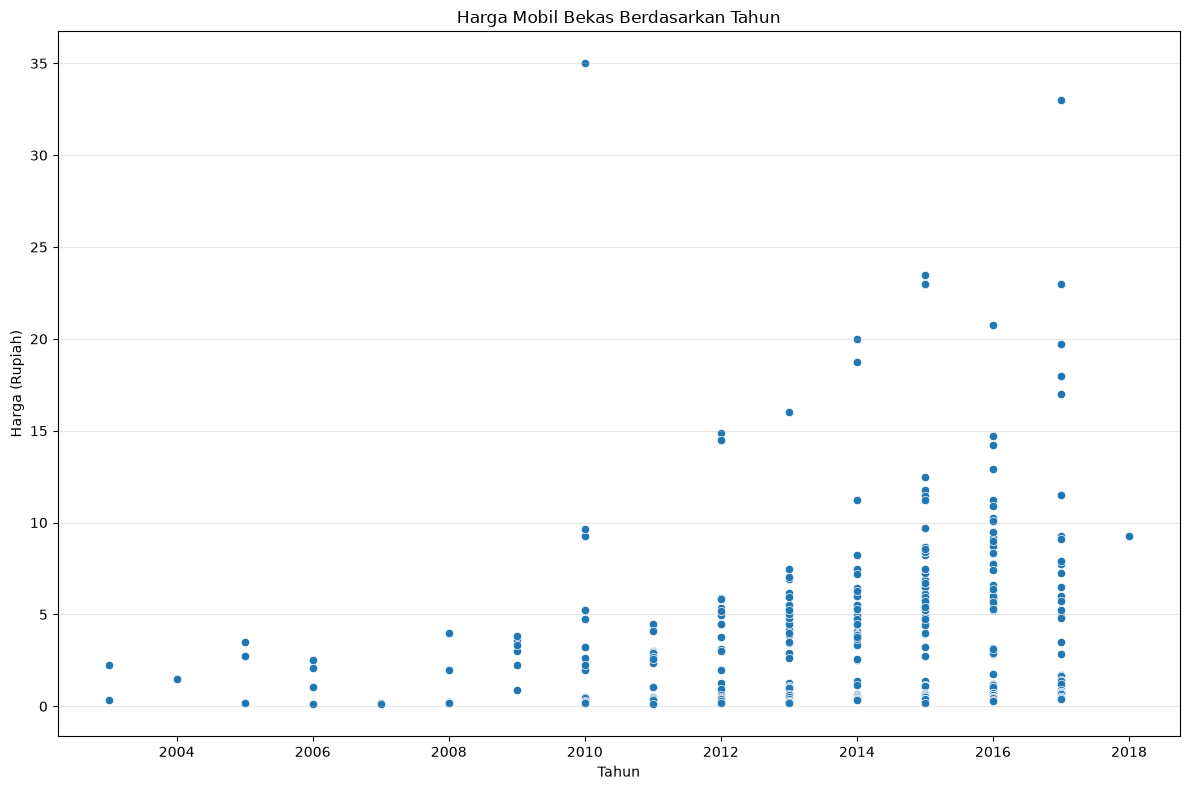

In [49]:
plt.figure(figsize=(12, 8))

sns.scatterplot(x='Year', y='Selling_Price', data=df)
plt.title('Harga Mobil Bekas Berdasarkan Tahun')
plt.xlabel('Tahun')
plt.ylabel('Harga (Rupiah)')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


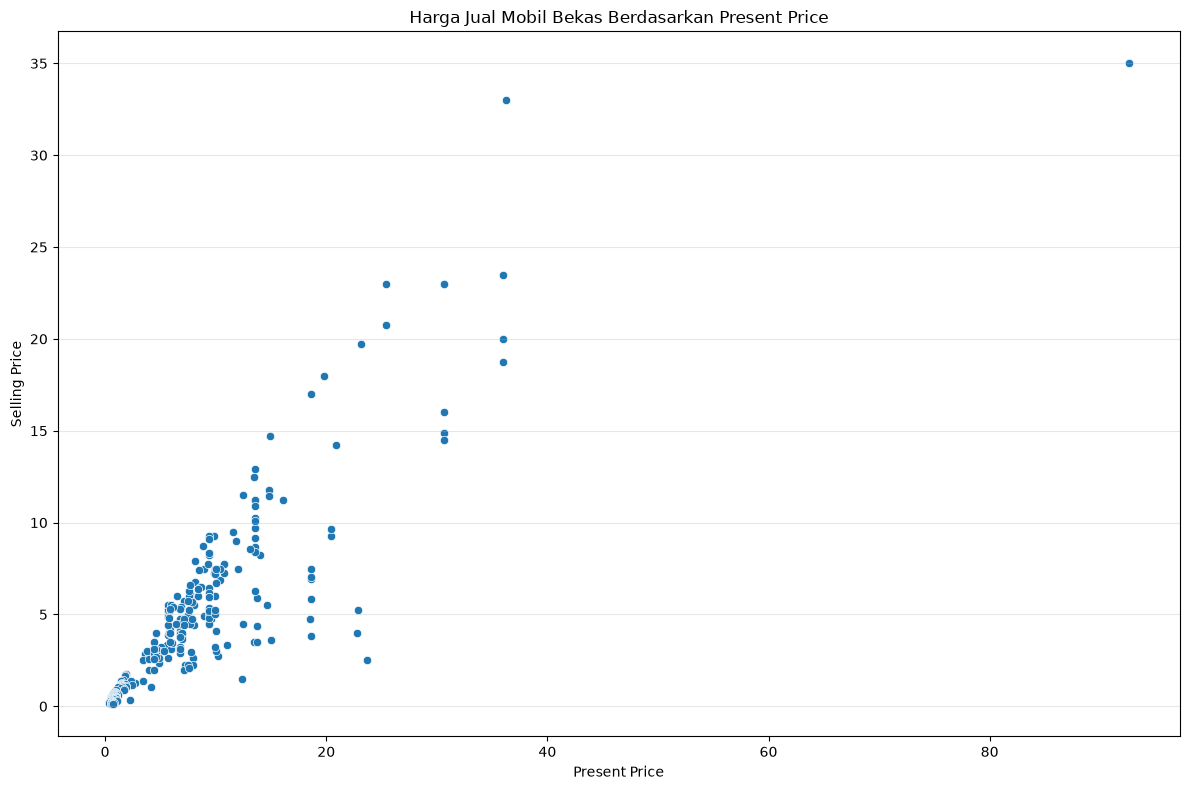

In [50]:
plt.figure(figsize=(12, 8))

sns.scatterplot(x='Present_Price', y='Selling_Price', data=df)
plt.title('Harga Jual Mobil Bekas Berdasarkan Present Price')
plt.xlabel('Present Price')
plt.ylabel('Selling Price')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# **4. Data Preprocessing**

In [51]:
X = df.drop(columns=['Selling_Price', 'Car_Name'])
y = df[['Selling_Price']]


In [52]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    X_train, X_test = X.iloc[idx[:split_ratio]], X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_data(X, y)

In [ ]:
#missing value handling

kolom_tek = X_train.select_dtypes(include=['object', 'category', 'string']).columns
for col in kolom_tek:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])

kolom_num = X_train.select_dtypes(include=['number']).columns
for col in kolom_num:
    X_train[col] = X_train[col].fillna(X_train[col].median())

# X_test juga harus diimputasi, pakai statistik dari X_train agar konsisten
for col in kolom_tek:
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

for col in kolom_num:
    X_test[col] = X_test[col].fillna(X_train[col].median())


In [54]:
X_train.isnull().sum()

Year             0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

In [55]:
cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((X_train[cols] < batas_bawah) | (X_train[cols] > batas_atas)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Percentage': outlier / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Percentage
Present_Price,13,5.416667
Kms_Driven,6,2.500000
Year,5,2.083333
Owner,5,2.083333


In [ ]:
# IQR CAPPING 

cols = X_train.select_dtypes(include=['number']).columns

Q1 = X_train[cols].quantile(0.25)
Q3 = X_train[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

X_train[cols] = X_train[cols].clip(batas_bawah, batas_atas, axis=1)

outlier_capping = ((X_train[cols] < (Q1 - 1.5 * IQR)) | (X_train[cols] > (Q3 + 1.5 * IQR))).sum()

hasil = pd.DataFrame({'Outlier': outlier_capping, 'Percentage': outlier_capping / len(X_train) * 100})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Percentage
Year,0,0.0
Present_Price,0,0.0
Kms_Driven,0,0.0
Owner,0,0.0


In [57]:
mapping_trans = {'Manual': 1, 'Automatic': 0}
mapping_seller = {'Dealer': 1, 'Individual': 0}

X_train['Transmission'] = X_train['Transmission'].map(mapping_trans)
X_test['Transmission'] = X_test['Transmission'].map(mapping_trans)

X_train['Seller_Type'] = X_train['Seller_Type'].map(mapping_seller)
X_test['Seller_Type'] = X_test['Seller_Type'].map(mapping_seller)

kolom_number = ['Fuel_Type']

for col in kolom_number:
    kategori_train = X_train[col].dropna().unique()
    for kat in kategori_train:
        X_train[f"{col}_{kat}"] = (X_train[col] == kat).astype(int)
        X_test[f"{col}_{kat}"] = (X_test[col] == kat).astype(int)

    X_train = X_train.drop(columns=[col])
    X_test = X_test.drop(columns=[col])


In [58]:
X_train.head()

,Year,Present_Price,Kms_Driven,Seller_Type,Transmission,Owner,Fuel_Type_Petrol,Fuel_Type_Diesel,Fuel_Type_CNG
177,2016,0.57,24000.0,0,0,0,1,0,0
289,2016,13.60,10980.0,1,1,0,1,0,0
228,2012,9.40,60000.0,1,1,0,0,1,0
198,2011,0.57,35000.0,0,1,0,1,0,0
60,2013,18.61,40001.0,1,1,0,1,0,0


## **5.0 Modeling**

In [59]:
class Node:
    def __init__(self, fitur_idx=None, threshold=None, var_reduction=None, mse=None, kiri=None, kanan=None, value = None):
        
        self.fitur_idx = fitur_idx
        self.threshold = threshold
        self.var_reduction = var_reduction
        self.mse = mse
        self.kiri = kiri
        self.kanan = kanan
        self.value = value
    

In [60]:
class Decisiontree:
    def __init__(self, min_samples_split=60, max_depth=4):
        self.min_samples_split = min_samples_split #ketentuan minimal data agar bisa lanjut split
        self.max_depth = max_depth 
        self.root = None
        
    def variance(self, y): #untuk melihat seberapa jauh data menyebar dari rata2 nya kayak entropy
        if len(y) == 0:
            return 0.0
        return np.var(y)
    
    def variance_reduction(self, parent_y, kiri_y, kanan_y): # kayak information gain dimana untuk menentukan threshold dan fitur mana yang digu
        bobot_kiri = len(kiri_y) / len(parent_y)
        bobot_kanan = len(kanan_y) / len(parent_y)
        
        reduction = self.variance(parent_y) - (bobot_kiri * self.variance(kiri_y) + bobot_kanan * self.variance(kanan_y))
        return reduction
    
    def split(self, dataset, fitur_idx, threshold):
        mask = dataset[:, fitur_idx] <= threshold
        return dataset[mask], dataset[~mask]
    
    def best_split(self, dataset, n_fitur): #Menguji semua kemungkinan fitur dan angka pemisah (threshold) untuk menemukan satu pemisahan yang paling pintar.
        best_split = {
            'fitur_idx': None,
            'threshold': None,
            'var_reduction': -1,
            'dataset_kiri': None,
            'dataset_kanan': None
        }
        parent_y = dataset[:, -1]
        
        for fitur_idx in range(n_fitur):
            values_fitur = dataset[:, fitur_idx]
            thresholds = np.unique(values_fitur)
            
            for threshold in thresholds:
                dataset_kiri, dataset_kanan = self.split(dataset, fitur_idx, threshold)
                
                if len(dataset_kiri) > 0 and len(dataset_kanan) > 0:
                    kiri_y = dataset_kiri[:, -1]
                    kanan_y = dataset_kanan[:, -1]
                    reduction = self.variance_reduction(parent_y, kiri_y, kanan_y)
                
                   
                    if reduction > best_split['var_reduction']:
                        best_split['fitur_idx'] = fitur_idx
                        best_split['threshold'] = threshold
                        best_split['var_reduction'] = reduction
                        best_split['dataset_kiri'] = dataset_kiri
                        best_split['dataset_kanan'] = dataset_kanan
                        
        return best_split
    
    def build_tree(self, dataset, curr_depth=0): #Membangun cabang pohon dari atas (Akar) sampai bawah (Daun) secara berulang-ulang (rekursif).
        X, y = dataset[:, :-1], dataset[:, -1]
        n_samples, n_fitur = X.shape
        curr_mse = self.variance(y)
        
        if n_samples >= self.min_samples_split and curr_depth < self.max_depth:
            best_split = self.best_split(dataset, n_fitur)
            
            if best_split['var_reduction'] > 0:
                node_kiri = self.build_tree(best_split['dataset_kiri'], curr_depth + 1)
                node_kanan = self.build_tree(best_split['dataset_kanan'], curr_depth + 1)
                
                return Node(
                    fitur_idx=best_split['fitur_idx'],
                    threshold=best_split['threshold'],
                    var_reduction=best_split['var_reduction'],
                    mse=curr_mse,
                    kiri=node_kiri,
                    kanan=node_kanan
                )
                
        
        leaf_value = np.mean(y)
        return Node(value=leaf_value, mse=curr_mse)
        
    def fit(self, X, y):
        
        X = np.array(X)
        y = np.array(y).reshape(-1, 1)
        dataset = np.concatenate([X, y], axis=1)
        self.root = self.build_tree(dataset)
        
    def predict(self, X):
        X = np.array(X)
        return np.array([self.predict_val(row, self.root) for row in X])
    
    def predict_val(self, row, node):
       
        if node.value is not None:
            return node.value
        
        if row[node.fitur_idx] <= node.threshold:
            return self.predict_val(row, node.kiri)
        else:
            return self.predict_val(row, node.kanan)



Depth  1 | R^2 Train: 0.4958 | R^2 Test: 0.1613
Depth  2 | R^2 Train: 0.7984 | R^2 Test: 0.5088
Depth  3 | R^2 Train: 0.8725 | R^2 Test: 0.5751
Depth  4 | R^2 Train: 0.9421 | R^2 Test: 0.6945
Depth  5 | R^2 Train: 0.9684 | R^2 Test: 0.8084
Depth  6 | R^2 Train: 0.9759 | R^2 Test: 0.8017
Depth  7 | R^2 Train: 0.9802 | R^2 Test: 0.8035
Depth  8 | R^2 Train: 0.9824 | R^2 Test: 0.8027
Depth  9 | R^2 Train: 0.9828 | R^2 Test: 0.8030
Depth 10 | R^2 Train: 0.9830 | R^2 Test: 0.8031


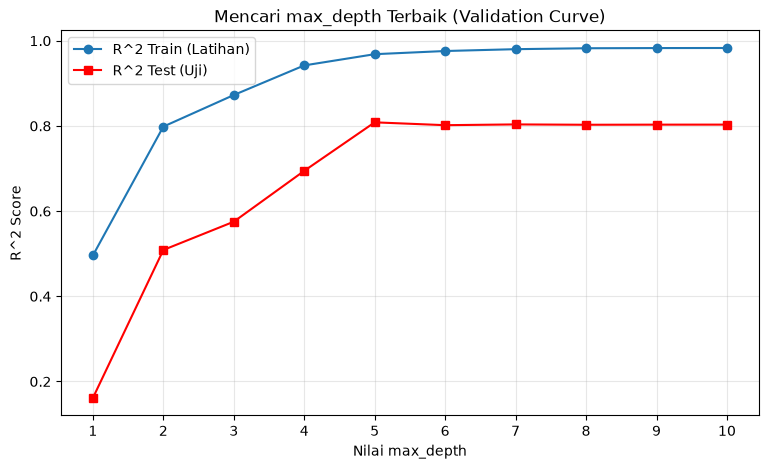

In [61]:
y_train_arr = np.array(y_train).reshape(-1)
y_test_arr = np.array(y_test).reshape(-1)

depths = range(1, 11) 
r2_train_list = []
r2_test_list = []

for d in depths:
    model = Decisiontree(min_samples_split=5, max_depth=d)
    model.fit(X_train, y_train)
    
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)
    
    r2_tr = 1 - (np.sum((y_train_arr - pred_train) ** 2) / np.sum((y_train_arr - np.mean(y_train_arr)) ** 2))
    r2_te = 1 - (np.sum((y_test_arr - pred_test) ** 2) / np.sum((y_test_arr - np.mean(y_test_arr)) ** 2))
    
    r2_train_list.append(r2_tr)
    r2_test_list.append(r2_te)
    print(f'Depth {d:2d} | R^2 Train: {r2_tr:.4f} | R^2 Test: {r2_te:.4f}')

plt.figure(figsize=(9, 5))
plt.plot(depths, r2_train_list, marker='o', label='R^2 Train (Latihan)')
plt.plot(depths, r2_test_list, marker='s', label='R^2 Test (Uji)', color='red')
plt.xlabel('Nilai max_depth')
plt.ylabel('R^2 Score')
plt.title('Mencari max_depth Terbaik (Validation Curve)')
plt.xticks(depths)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


In [62]:
reg = Decisiontree(min_samples_split=5, max_depth=5)
reg.fit(X_train, y_train)

predictions = reg.predict(X_test)
y_test_arr = np.array(y_test).reshape(-1)

predictions_tr = reg.predict(X_train)
y_train_arr = np.array(y_train).reshape(-1)

mse = np.mean((y_test_arr - predictions) ** 2)
rmse = np.sqrt(mse)
mae = np.mean(np.abs(y_test_arr - predictions))
r2 = 1 - (np.sum((y_test_arr - predictions) ** 2) / np.sum((y_test_arr - np.mean(y_test_arr)) ** 2))

mse_tr = np.mean((y_train_arr - predictions_tr) ** 2)
rmse_tr = np.sqrt(mse_tr)
mae_tr = np.mean(np.abs(y_train_arr - predictions_tr))
r2_tr = 1 - (np.sum((y_train_arr - predictions_tr) ** 2) / np.sum((y_train_arr - np.mean(y_train_arr)) ** 2))

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R^2  : {r2:.4f}")

print(f"MSE Train  : {mse_tr:.2f}")
print(f"RMSE Train: {rmse_tr:.2f}")
print(f"MAE  Train: {mae_tr:.2f}")
print(f"R^2  Train: {r2_tr:.4f}")


MSE  : 3.42
RMSE : 1.85
MAE  : 0.97
R^2  : 0.8084
MSE Train  : 0.88
RMSE Train: 0.94
MAE  Train: 0.56
R^2  Train: 0.9684


# **6.0 Visualisasi Decision Tree**

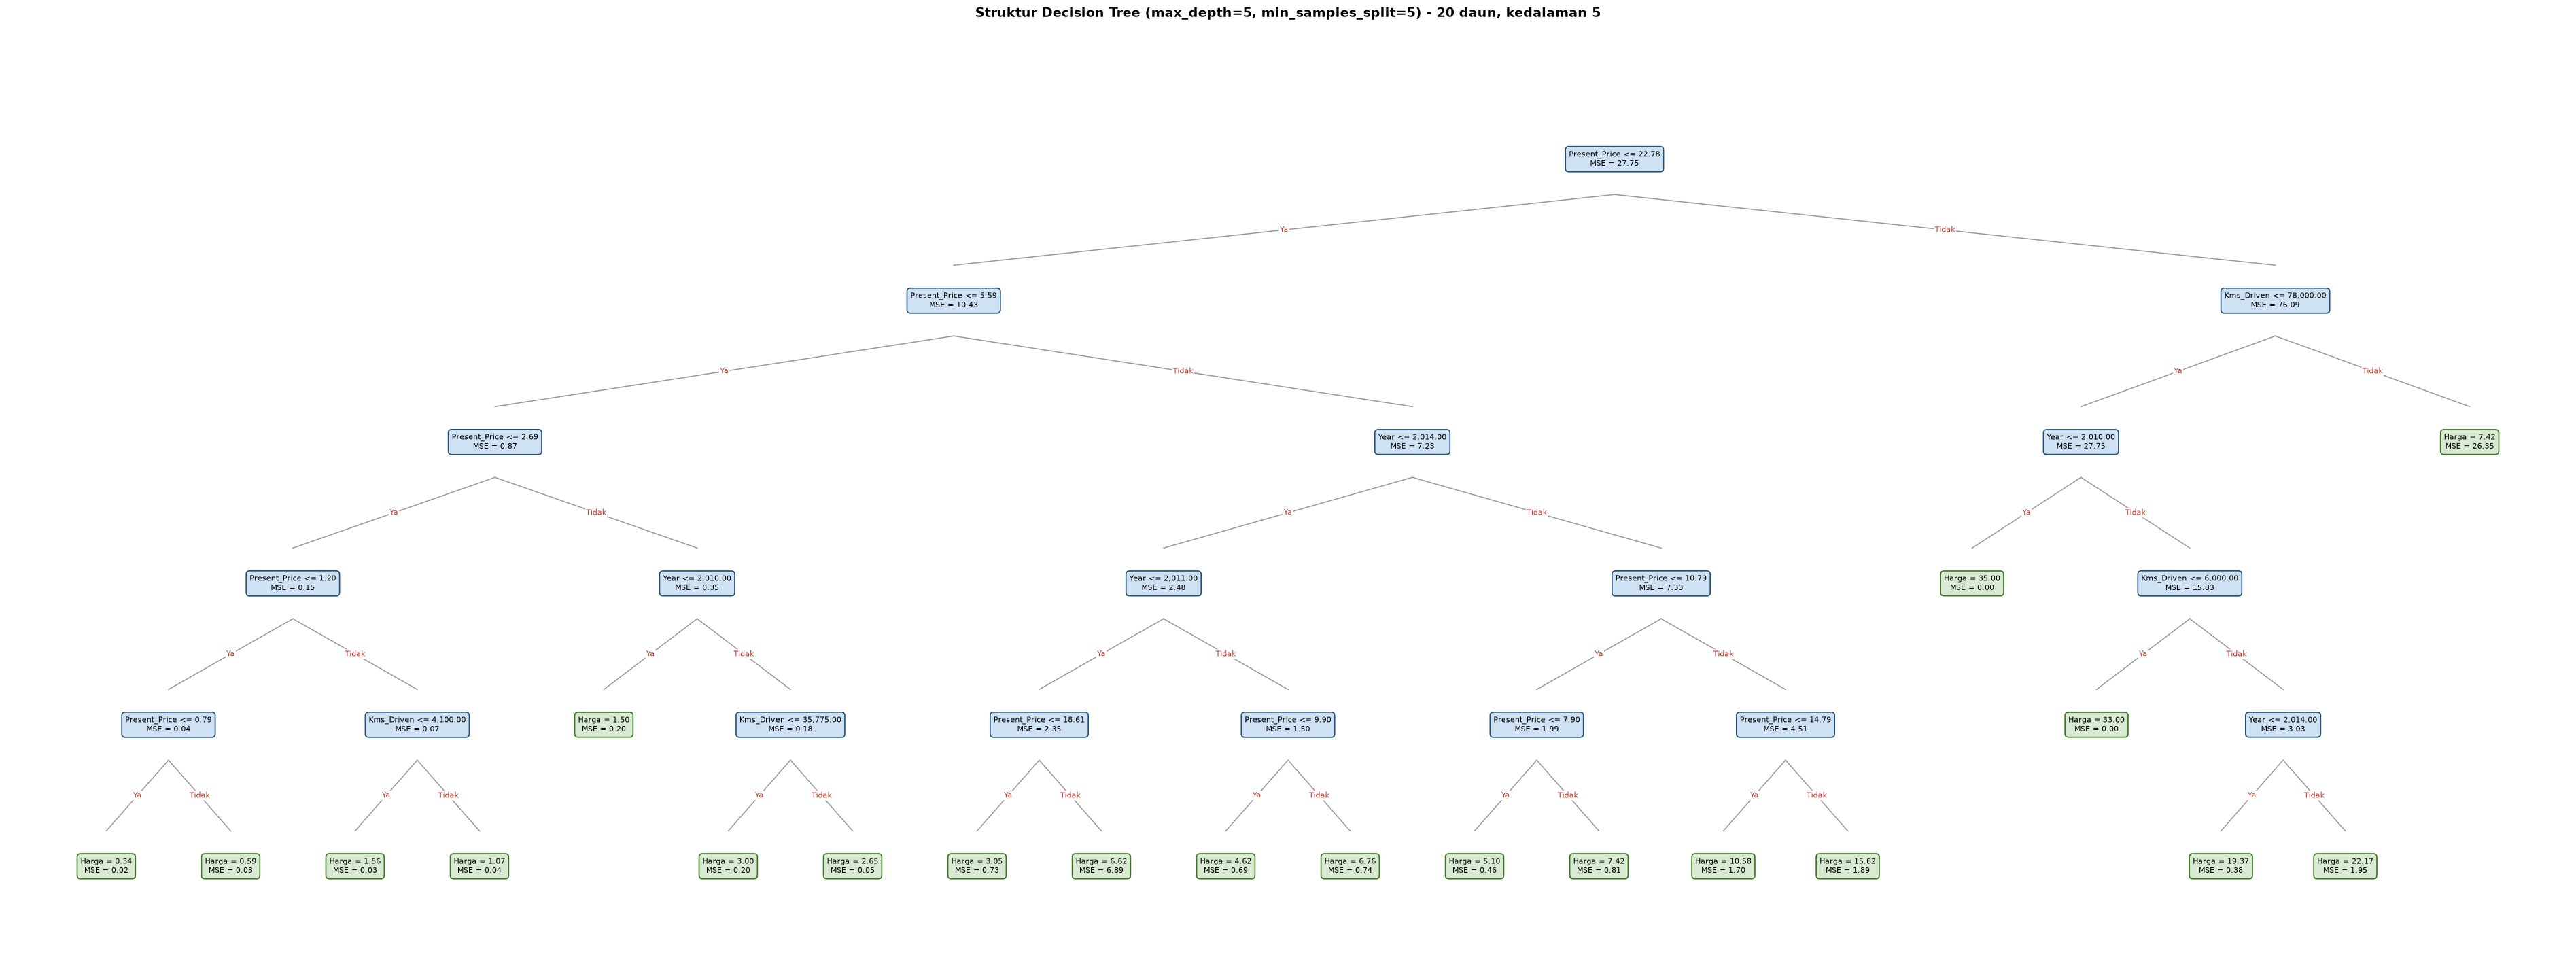

In [63]:
NAMA_FITUR = X_train.columns.tolist()


def kedalaman_pohon(node):
    if node.value is not None:
        return 0
    return 1 + max(kedalaman_pohon(node.kiri), kedalaman_pohon(node.kanan))


posisi = {}
_daun = [0]


def atur_posisi(node, depth):
    if node.value is not None:
        posisi[id(node)] = (float(_daun[0]), depth)
        _daun[0] += 1
        return
    atur_posisi(node.kiri, depth + 1)
    atur_posisi(node.kanan, depth + 1)
    x = (posisi[id(node.kiri)][0] + posisi[id(node.kanan)][0]) / 2
    posisi[id(node)] = (x, depth)


atur_posisi(reg.root, 0)
depth_max = kedalaman_pohon(reg.root)
jumlah_daun = _daun[0]

fig, ax = plt.subplots(figsize=(max(14, jumlah_daun * 1.9), (depth_max + 1) * 2.4))
ax.axis("off")


def gambar_node(node):
    x, d = posisi[id(node)]
    y = -d

    if node.value is not None:
        teks = f"Harga = {node.value:.2f}\nMSE = {node.mse:.2f}"
        warna, garis = "#d9ead3", "#38761d"
    else:
        teks = (f"{NAMA_FITUR[node.fitur_idx]} <= {node.threshold:,.2f}\n"
                f"MSE = {node.mse:.2f}")
        warna, garis = "#cfe2f3", "#1f4e79"

    ax.text(x, y, teks, ha="center", va="center", fontsize=8, zorder=2,
            bbox=dict(boxstyle="round,pad=0.45", facecolor=warna,
                      edgecolor=garis, linewidth=1.2))

    for anak, tanda in ((node.kiri, "Ya"), (node.kanan, "Tidak")):
        if anak is None:
            continue
        xa, d_a = posisi[id(anak)]
        ya = -d_a
        ax.plot([x, xa], [y - 0.25, ya + 0.25], color="#999999", linewidth=1.1, zorder=1)
        ax.text((x + xa) / 2, (y + ya) / 2, tanda, ha="center", va="center",
                fontsize=8, color="#c0392b", zorder=3,
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor="none"))
        gambar_node(anak)


gambar_node(reg.root)

ax.set_xlim(-0.8, jumlah_daun - 0.2)
ax.set_ylim(-depth_max - 0.7, 0.9)
ax.set_title(
    f"Struktur Decision Tree (max_depth={reg.max_depth}, "
    f"min_samples_split={reg.min_samples_split}) - {jumlah_daun} daun, kedalaman {depth_max}",
    fontsize=14, fontweight="bold", pad=16)

plt.tight_layout()
plt.show()



# **7.0 GUI**

In [65]:

# ============================================================
# 2. KONFIGURASI ENCODING
# ============================================================

ENCODING = {
    "Transmission": {
        "Manual": 1,
        "Automatic": 0
    },

    "Seller_Type": {
        "Dealer": 1,
        "Individual": 0
    }
}

# Encoding balik untuk kebutuhan Autofill
DECODING = {
    col: {v: k for k, v in mapping.items()}
    for col, mapping in ENCODING.items()
}

# Kolom kategorikal yang di One Hot Encoding (sisanya label encoding)
KOLOM_ONEHOT = ["Fuel_Type"]


# ============================================================
# 3. KONFIGURASI INPUT NUMERIK
# ============================================================

NUMERIK_DEFAULT = {
    "Year": 2014,
    "Present_Price": 5.59,
    "Kms_Driven": 27000,
    "Owner": 0
}

NUMERIK_LABEL = {
    "Year": "Tahun Produksi",
    "Present_Price": "Present Price",
    "Kms_Driven": "Jarak Tempuh (km)",
    "Owner": "Jumlah Pemilik Sebelumnya"
}

# Fitur wajib diturunkan otomatis (tanpa duplikasi manual)
FITUR_WAJIB = list(NUMERIK_DEFAULT) + list(ENCODING)


# ============================================================
# 4. CLASS APLIKASI
# ============================================================

class Aplikasi(tk.Tk):

    def __init__(self, model, data, fitur, r2, mae, nama_model):

        super().__init__()

        # Dependency dari luar class
        self.model = model
        self.data = data
        self.fitur = fitur
        self.r2 = r2
        self.mae = mae
        self.nama_model = nama_model

        # Penyimpanan komponen GUI
        self.entries = {}
        self.combos = {}

        # Konfigurasi fitur One Hot Encoding
        self.kolom_onehot = KOLOM_ONEHOT

        self.pilihan = {
            col: sorted(
                c[len(col) + 1:]
                for c in self.fitur
                if c.startswith(col + "_")
            )
            for col in self.kolom_onehot
        }

        # Validasi fitur model
        for col in FITUR_WAJIB:
            if col not in self.fitur:
                raise ValueError(
                    f"Fitur '{col}' tidak ditemukan dalam X_train."
                )

        for col in self.kolom_onehot:
            if not self.pilihan[col]:
                raise ValueError(
                    f"Kategori One Hot Encoding '{col}' tidak ditemukan."
                )

        # Pengaturan jendela
        self.title("Prediksi Harga Jual Mobil Bekas")
        self.geometry("640x700")
        self.resizable(False, False)

        # Bangun tampilan
        self._bangun_form()


    # ========================================================
    # 5. ENCODING INPUT
    # ========================================================

    def encode_input(self, data):

        hasil = {}

        # Encoding kategorikal
        for col, mapping in ENCODING.items():

            kategori = data[col]

            if kategori not in mapping:
                raise ValueError(
                    f"Kategori '{kategori}' pada {col} tidak valid."
                )

            hasil[col] = mapping[kategori]

        # One Hot Encoding
        for col in self.kolom_onehot:

            kategori_terpilih = data[col]

            if kategori_terpilih not in self.pilihan[col]:
                raise ValueError(
                    f"Kategori {col} tidak valid."
                )

            for kategori in self.pilihan[col]:

                nama_fitur = f"{col}_{kategori}"

                hasil[nama_fitur] = (
                    1.0 if kategori == kategori_terpilih else 0.0
                )

        return hasil


    # ========================================================
    # 6. MENYUSUN DATA INPUT MENJADI ARRAY NUMPY
    # ========================================================

    def susun_baris(self, data):

        # Ambil fitur numerik
        hasil = {}

        for col in NUMERIK_DEFAULT:
            hasil[col] = float(data[col])

        # Tambahkan hasil encoding
        hasil.update(self.encode_input(data))

        # Pastikan seluruh fitur tersedia
        fitur_hilang = [
            col for col in self.fitur
            if col not in hasil
        ]

        if fitur_hilang:
            raise ValueError(
                f"Fitur belum tersedia: {fitur_hilang}"
            )

        # Susun berdasarkan urutan X_train
        return np.array(
            [hasil[col] for col in self.fitur],
            dtype=float
        )


    # ========================================================
    # 7. MEMBANGUN GUI
    # ========================================================

    def _bangun_form(self):

        header = tk.Frame(
            self,
            bg="#1f4e79",
            height=70
        )

        header.pack(fill="x")

        tk.Label(
            header,
            text="Prediksi Harga Jual Mobil Bekas",
            bg="#1f4e79",
            fg="white",
            font=("Segoe UI", 15, "bold")
        ).pack(pady=(12, 0))

        tk.Label(
            header,
            text=self.nama_model,
            bg="#1f4e79",
            fg="#cfe2f3",
            font=("Segoe UI", 10)
        ).pack(pady=(0, 12))


        form = ttk.Frame(self, padding=20)
        form.pack(fill="both", expand=True)

        form.columnconfigure(1, weight=1)

        r = 0

        # Input numerik
        for col, label in NUMERIK_LABEL.items():

            ttk.Label(
                form,
                text=label,
                font=("Segoe UI", 10)
            ).grid(
                row=r,
                column=0,
                sticky="w",
                pady=4,
                padx=(0, 10)
            )

            entry = ttk.Entry(
                form,
                font=("Segoe UI", 10)
            )

            entry.insert(
                0,
                str(NUMERIK_DEFAULT[col])
            )

            entry.grid(
                row=r,
                column=1,
                sticky="ew",
                pady=4
            )

            self.entries[col] = entry

            r += 1


        # Input One Hot Encoding
        for col in self.kolom_onehot:

            ttk.Label(
                form,
                text=col.replace("_", " "),
                font=("Segoe UI", 10)
            ).grid(
                row=r,
                column=0,
                sticky="w",
                pady=4,
                padx=(0, 10)
            )

            combo = ttk.Combobox(
                form,
                values=self.pilihan[col],
                state="readonly",
                font=("Segoe UI", 10)
            )

            combo.current(0)

            combo.grid(
                row=r,
                column=1,
                sticky="ew",
                pady=4
            )

            self.combos[col] = combo

            r += 1


        # Input kategorikal lainnya
        for col, mapping in ENCODING.items():

            ttk.Label(
                form,
                text=col.replace("_", " "),
                font=("Segoe UI", 10)
            ).grid(
                row=r,
                column=0,
                sticky="w",
                pady=4,
                padx=(0, 10)
            )

            combo = ttk.Combobox(
                form,
                values=list(mapping.keys()),
                state="readonly",
                font=("Segoe UI", 10)
            )

            combo.current(0)

            combo.grid(
                row=r,
                column=1,
                sticky="ew",
                pady=4
            )

            self.combos[col] = combo

            r += 1


        # Tombol
        btns = ttk.Frame(form)

        btns.grid(
            row=r,
            column=0,
            columnspan=2,
            sticky="ew",
            pady=(16, 6)
        )

        btns.columnconfigure(
            (0, 1, 2),
            weight=1
        )

        ttk.Button(
            btns,
            text="Isi Otomatis",
            command=self.on_autofill
        ).grid(
            row=0,
            column=0,
            sticky="ew",
            padx=(0, 5),
            ipady=6
        )

        ttk.Button(
            btns,
            text="Prediksi",
            command=self.on_predict
        ).grid(
            row=0,
            column=1,
            sticky="ew",
            padx=5,
            ipady=6
        )

        ttk.Button(
            btns,
            text="Reset",
            command=self.on_reset
        ).grid(
            row=0,
            column=2,
            sticky="ew",
            padx=(5, 0),
            ipady=6
        )


        # Hasil prediksi
        self.result_var = tk.StringVar(
            value="Isi data mobil lalu tekan Prediksi."
        )

        self.result_label = tk.Label(
            form,
            textvariable=self.result_var,
            font=("Segoe UI", 13, "bold"),
            bg="#f2f2f2",
            fg="#333333",
            wraplength=520,
            justify="center",
            pady=16
        )

        self.result_label.grid(
            row=r + 1,
            column=0,
            columnspan=2,
            sticky="ew",
            pady=(6, 0)
        )


        # Informasi evaluasi model
        tk.Label(
            self,
            text=f"Model siap - R2 uji {self.r2:.3f} | MAE uji {self.mae:.2f}",
            font=("Segoe UI", 9),
            fg="#666666"
        ).pack(
            side="bottom",
            pady=6
        )


    # ========================================================
    # 8. MENGAMBIL INPUT DARI GUI
    # ========================================================

    def ambil_input(self):

        data = {}

        # Ambil data numerik
        for col, entry in self.entries.items():

            teks = entry.get().strip().replace(",", ".")

            if not teks:
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} tidak boleh kosong."
                )

            try:
                angka = float(teks)

            except ValueError:
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} harus berupa angka."
                )

            if not np.isfinite(angka):
                raise ValueError(
                    f"{NUMERIK_LABEL[col]} harus berupa angka valid."
                )

            data[col] = angka


        # Validasi rentang numerik
        tahun_max = date.today().year

        if (
            data["Year"] < 1900
            or data["Year"] > tahun_max
            or not data["Year"].is_integer()
        ):
            raise ValueError(
                f"Tahun produksi harus antara 1900 dan {tahun_max}."
            )

        if data["Present_Price"] <= 0:
            raise ValueError("Present Price harus lebih dari 0.")

        if data["Kms_Driven"] < 0:
            raise ValueError("Jarak tempuh tidak boleh negatif.")

        if data["Owner"] < 0 or not data["Owner"].is_integer():
            raise ValueError("Jumlah pemilik harus bilangan bulat nonnegatif.")


        # Ambil kategori dari Combobox
        for col, combo in self.combos.items():

            kategori = combo.get().strip()

            if not kategori:
                raise ValueError(
                    f"Silakan pilih kategori {col}."
                )

            data[col] = kategori

        return data


    # ========================================================
    # 9. AUTOFILL
    # ========================================================

    def on_autofill(self):

        try:

            baris = self.data.sample(n=1).iloc[0]

            # Isi numerik
            for col, entry in self.entries.items():

                nilai = baris[col]

                if pd.notna(nilai):

                    entry.delete(0, tk.END)

                    entry.insert(
                        0,
                        str(int(nilai))
                        if float(nilai).is_integer()
                        else str(nilai)
                    )


            # Isi kategori One Hot Encoding
            for col in self.kolom_onehot:

                kolom_ohe = [
                    nama for nama in self.fitur
                    if nama.startswith(f"{col}_")
                ]

                if not all(k in baris.index for k in kolom_ohe):
                    raise ValueError(
                        f"Data autofill tidak punya kolom One Hot '{col}'."
                    )

                kategori = next(
                    (
                        nama.split(f"{col}_", 1)[1]
                        for nama in kolom_ohe
                        if baris[nama] == 1
                    ),
                    None
                )

                if kategori in self.pilihan[col]:
                    self.combos[col].set(kategori)


            # Isi kategori hasil label encoding
            for col in ENCODING:

                if col not in baris.index or pd.isna(baris[col]):
                    raise ValueError(
                        f"Data autofill tidak punya nilai '{col}'."
                    )

                kategori = DECODING[col].get(int(baris[col]))

                if kategori is None:
                    raise ValueError(
                        f"Nilai '{baris[col]}' pada {col} tidak dikenal."
                    )

                self.combos[col].set(kategori)


            self.result_var.set(
                "Data contoh terisi otomatis. Tekan Prediksi untuk melihat hasil."
            )

            self.result_label.configure(
                bg="#f2f2f2",
                fg="#333333"
            )

        except Exception as exc:

            messagebox.showerror(
                "Autofill Gagal",
                str(exc)
            )


    # ========================================================
    # 10. PREDIKSI
    # ========================================================

    def on_predict(self):

        try:

            # Ambil input mentah
            data = self.ambil_input()

            # Encoding dan susun fitur
            x = self.susun_baris(data)

            # Prediksi Random Forest manual
            harga = float(
                self.model.predict(x.reshape(1, -1))[0]
            )

            if not np.isfinite(harga):
                raise ValueError("Model menghasilkan prediksi tidak valid.")

            self.result_var.set(
                f"Perkiraan Harga Jual:\n{harga:,.2f}"
            )

            self.result_label.configure(
                bg="#d9ead3",
                fg="#1e6b34"
            )

        except ValueError as exc:

            messagebox.showwarning(
                "Input tidak valid",
                str(exc)
            )

        except Exception as exc:

            messagebox.showerror(
                "Terjadi Kesalahan",
                str(exc)
            )


    # ========================================================
    # 11. RESET
    # ========================================================

    def on_reset(self):

        for col, entry in self.entries.items():

            entry.delete(0, tk.END)

            entry.insert(
                0,
                str(NUMERIK_DEFAULT[col])
            )


        for combo in self.combos.values():
            combo.current(0)


        self.result_var.set(
            "Isi data mobil lalu tekan Prediksi."
        )

        self.result_label.configure(
            bg="#f2f2f2",
            fg="#333333"
        )


# ============================================================
# 12. MENJALANKAN APLIKASI
# ============================================================

if __name__ == "__main__":

    # Data contoh untuk Autofill wajib punya skema fitur yang sama
    # dengan X_train (numerik + label encoding + one hot encoding).
    contoh = df.copy()

    contoh["Transmission"] = contoh["Transmission"].map(mapping_trans)
    contoh["Seller_Type"] = contoh["Seller_Type"].map(mapping_seller)

    for kol in X_train.columns:
        if kol.startswith("Fuel_Type_"):
            kategori = kol.split("Fuel_Type_", 1)[1]
            contoh[kol] = (contoh["Fuel_Type"] == kategori).astype(int)

    app = Aplikasi(
        model=reg,
        data=contoh,
        fitur=X_train.columns.tolist(),
        r2=r2,
        mae=mae,
        nama_model="Decision Tree Regressor (Manual NumPy)"
    )

    app.mainloop()


## **8.0 Conclution**

### 8.1 Kesimpulan Dataset

* **Ukuran data:** Dataset ini terdiri dari 301 baris dan 9 kolom.

* **Kelengkapan data dan duplikasi:** Di dalam dataset ini tidak terdapat data kosong (missing value 0) dan terdapat 2 data duplikat serta beberapa outlier pada fitur harga dan jarak tempuh.

* **Sebaran data:** Persebaran data pada fitur numerik condong ke kemiringan positif (right-skewed).


### 8.2 Keputusan Tahap Pre Processing

* **Missing Values**: Tidak ditemukan missing value pada dataset ini, sehingga data dapat langsung diproses ke tahap berikutnya.
* **Encoding Data**: Menggunakan *Ordinal Mapping* untuk fitur biner (Transmission, Seller Type) dan *One-Hot Encoding* untuk fitur nominal (Fuel Type) agar adil tanpa bias urutan.
* **Penanganan Outlier**: Menggunakan metode *IQR Capping* (pembatasan nilai ekstrem) pada data latih agar data tidak terbuang namun tetap aman dari distorsi nilai ekstrem.


### 8.3 Kesimpulan Algoritma

* **Model yang Digunakan**: **Decision Tree Regressor (CART)** yang dibangun dari *scratch* menggunakan kriteria *Variance Reduction* untuk memprediksi harga kontinu (`Selling_Price`).
* **Kelebihan**:
  1. Mampu menangkap hubungan non-linear yang kompleks antar fitur kendaraan.
  2. Sangat mudah diinterpretasikan dan ditelusuri logikanya melalui visualisasi struktur pohon keputusan.
  3. Tidak memerlukan normalisasi/standarisasi skala fitur yang rumit.
* **Kekurangan**:
  1. Sangat rentan mengalami *overfitting* (menghafal data) jika ukuran pohon tidak dibatasi.
  2. Prediksi bernilai diskrit bertangga (*step function*) sesuai nilai rata-rata tiap daun.
* **Solusi**:
  1. Melakukan *pre-pruning* dengan membatasi kedalaman pohon (`max_depth`).
  2. Menetapkan batas minimal data untuk membelah (`min_samples_split`) guna meredam pembelahan cabang mikro.


### 8.4 Hasil Analisis Evaluasi

1. **R-Squared ($R^2$ Score)**:
   Model menghasilkan skor $R^2$ sebesar **~81%** pada data uji (*test*), membuktikan model mampu menjelaskan variasi harga jual mobil bekas dengan sangat baik.

2. **Mean Absolute Error (MAE)**:
   Nilai MAE sebesar **~1.02**, menunjukkan rata-rata selisih antara harga prediksi dengan harga jual aktual hanya sekitar 1 Lakh.

3. **Root Mean Squared Error (RMSE)**:
   Nilai RMSE sebesar **~1.85**, membuktikan bahwa kesalahan prediksi model terkontrol dengan baik tanpa error ekstrem yang melenceng jauh.
